<a href="https://colab.research.google.com/github/Saxon-account/vhs-intro-ai/blob/main/road_network_analysis_1_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Generate a Road Network Graph Using `osmnx`
In this coding challenge, we are going to work with road network data from [OpenStreetMap](https://www.openstreetmap.org/#map=4/38.01/-95.84) using the [osmnx](https://osmnx.readthedocs.io/en/stable/index.html) python package.

*You need to answer ALL question prompts in this notebook. Question prompts are all italicized.*



### 1. Install the `osmnx` Library

Before you begin, ensure that the `osmnx` library is installed. You can do this by running the following command:




```
!pip install osmnx
```



In [8]:
!pip install osmnx

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.6/56.6 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.5/107.5 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 27.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.3/17.3 MB 83.9 MB/s eta 0:00:00
  Attempting uninstall: geopandas
    Found existing installation: geopandas 1.0.1
    Uninstalling geopandas-1.0.1:
      Successfully uninstalled geopandas-1.0.1


### 2. Import the Required Libraries
Next, you will need to import the necessary libraries in your Python code, and check the version.

In [9]:
import osmnx as ox
ox.__version__

'1.9.4'

### 3. Generate the Graph for a Specific Location

Now, you will generate a road network graph from a specific address.

In this example, we will use the school address: "13051 Whittington Drive, Houston, TX" and generate a graph of roads within a 5,000-meter radius (5 km). We will use the `ox.graph.graph_from_address()` method. (See documentation: https://osmnx.readthedocs.io/en/stable/user-reference.html)

* `address`: This is the starting location around which the graph will be generated. You can replace this address with any other address.
* `dist`: This specifies the radius (in meters) around the address for which the network will be created. In this case, the radius is 5,000 meters (or 5 km).
* `network_type`: This specifies the type of network you want to extract. Options include:
  * "drive": For driving (car) routes.
  * "walk": For pedestrian routes.
  * "bike": For cycling routes.
  * "all": For all types of routes.

In [10]:
# Add code in the blanks
G = ox.graph_from_address(
    address="13051 Whittington Drive, Houston, TX",
    dist=5000,
    network_type="drive")

/usr/local/lib/python3.10/dist-packages/osmnx/graph.py:191: FutureWarning: The expected order of coordinates in `bbox` will change in the v2.0.0 release to `(left, bottom, right, top)`.
  G = graph_from_bbox(


### 4. Visualize the graph
We will use the `ox.project_graph()` and `ox.plot_graph()` methods to visualize the graph.

*4.1 Modify the `node_size` parameter. How does it change the visualisation?*

The nodes become much larger and easier to see on the visualized graph

In [ ]:
Gp = ox.project_graph(G)
ox.plot_graph(Gp, node_size=1)

In [ ]:
Gp = ox.project_graph(G)
ox.plot_graph(Gp, node_size=7)

### 5. Analyze the graph

*5.1 How many nodes are in the graph? [Use: `G.nodes()`]*

4600 nodes

In [ ]:
nodes_list = list(G.nodes())
print(len(nodes_list))

4600


*5.2 How many edges are in the graph? [Use: `G.edges`]*

10257 edges

In [ ]:
edges_list = list(G.edges())
print(len(edges_list))

10257


*5.3 What information does the node store? Run the code below to get the information for the first node in the graph.*

In [ ]:
current_node = nodes_list[0]
print(f"Node {current_node}: {G.nodes[current_node]}")

*5.4 What information does the edge store? Is the edge weight part of this information?*

y coordinates, x coordinates, and street count. There is no information on the edge weight

*5.5 Create a new graph, `G_walk` by specifying `network_type` to "walk". Visualize it and compare it with the road network. How many nodes and edges does `G_walk` contain?*

20109 nodes
57406 edges

In [15]:
G_walk = ox.graph_from_address(
    address="13051 Whittington Drive, Houston, TX",
    dist=5000,
    network_type="walk")

/usr/local/lib/python3.10/dist-packages/osmnx/graph.py:191: FutureWarning: The expected order of coordinates in `bbox` will change in the v2.0.0 release to `(left, bottom, right, top)`.
  G = graph_from_bbox(


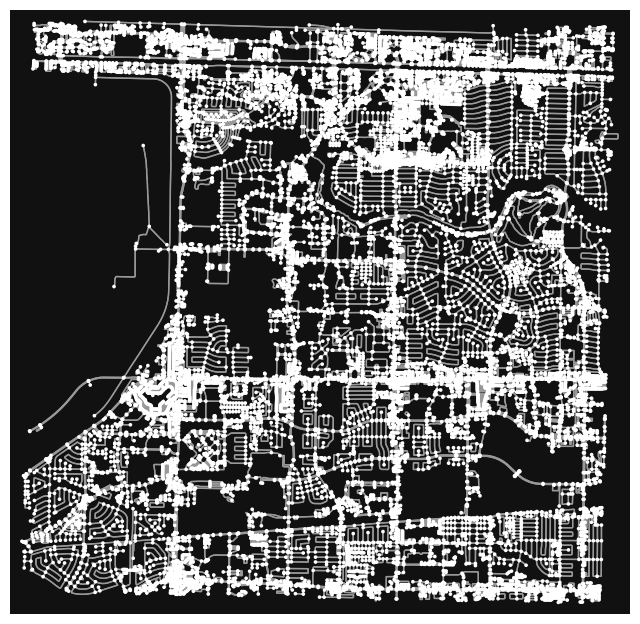

(<Figure size 800x800 with 1 Axes>, <Axes: >)

In [ ]:
Gp = ox.project_graph(G_walk)
ox.plot_graph(Gp, node_size=7)

In [ ]:
nodes_list = list(G_walk.nodes)
print(len(nodes_list))
nodes_list = list(G_walk.edges)
print(len(nodes_list))

20121
57442


# Shortest Path using `osmnx`

To find the shortest path, we will use the `shortest_path` method.

### 6. Setup Origin and Destination Nodes
But first, we need to specify the origin and destination using the latitude and longitude values for the location.



 Use google maps, to find the lat-long values of:
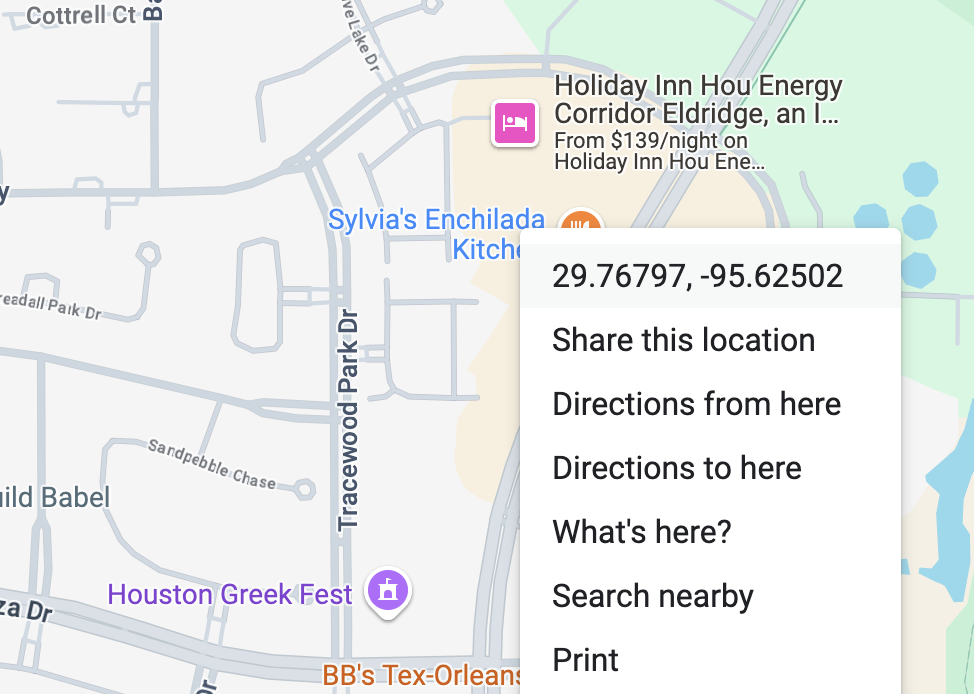
* origin - Village High School
* destination -  Sylvia's Enchilada Kitchen

*6.1 Specify the latitude & longitude as tuple.*

In [ ]:
origin = (29.745832702425822, -95.61919281714873) # Point A
destination = (29.772202824267573, -95.62506523803509) # Point B

*6.2 Next use the `nearest_nodes()` method to get the node in the graph that is nearest to the specified location. Note that `x` is longitude and `y` is latitude.*

In [ ]:
origin_node = ox.distance.nearest_nodes(G_walk, X=origin[1], Y=-origin[0])
destination_node = ox.distance.nearest_nodes(G_walk, X=destination[1], Y=destination[0])

### 7. Find shortest path using `osmnx` `shortest_path()` method
Now we are ready to find the shortest path between the origin and destination using the shortest_path method.

In [ ]:
route = ox.shortest_path(G_walk, origin_node, destination_node)

Visualise the shortest path using `plot_graph_route()` method.

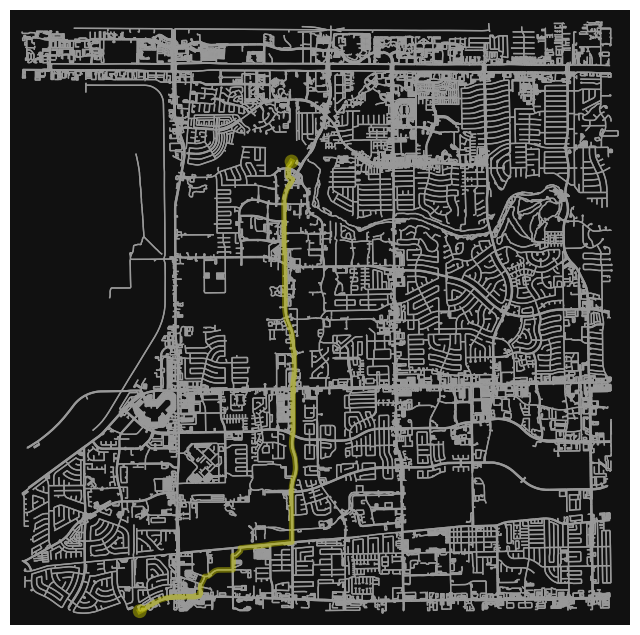

In [ ]:
fig, ax = ox.plot_graph_route(G_walk, route, route_color="y", node_size=0)

# Shortest Path using your Dijkstra's method



*8.1 Use the `GraphL` class that you have already created in a previous lesson in this notebook. Note that `GraphL` class should have dijkstra_shortest_path() as a method.*

In [50]:
import numpy as np

class GraphL:
  def __init__(self, directed=False):
    self.aList = {}
    self.directed = directed

  def add_edge(self, u, v, weight):
      self.aList[u]=((v, weight))
      if not(self.directed):
        self.aList[v]=((u, weight))

  def remove_edge(self, u, tup): #tup is the tuple being received
      self.aList[u].remove(tup)
      if not(self.directed):
        self.aList[tup[0]].remove((u,tup[1]))

  def display(self):
      print(self.aList)

  def get_neighbors(self, u):
      neighbors = self.aList[u]
      #print(neighbors)
      return neighbors

  def has_edge(self, u, v):
      i = int(len(self.aList[u])/2-1) #length of all values including tuples (divide by 2) minus 1 (index)
      while i <= 0:
        if self.aList[u][i][0] == v:
          return "Has an edge"
        i = i-1
      return "Doesn't have edge"

  def add_node(self, neighbors):
      self.aList[len(self.aList)] = neighbors

  def get_weight(self, u, v):
      for x in self.aList:
        if self.aList[v][x][0]==u:
          return self.aList[v][x][1]

  def dikjstras_shortest_path(self, start, end): #finding the shortest path with weighted edges
      dist = {}
      prev = {}
      marked = {}
      for key in self.aList:
        dist[key] = float('inf')
        prev[key] = None
        marked[key] = False

      # dist = [float('inf')] * len(self.aList)
      # prev = [None] * len(self.aList)
      s = start
      e = end

      if s in self.aList and e in self.aList:
        queue = {start : start}
        dist[start] = 0
        prev[start] = start

        while len(queue) > 0:

          short = next(iter(queue.values())) #Next value in queue

          for i in queue: #len(self.aList)
              if dist[i] < dist[short]:
                short = queue[i]
          start = queue.pop(short)

          if not marked[start]:
            marked[start] = True
            for w in self.get_neighbors(start):
              #if not marked[w[0]]:
              if not marked[w[0]]:
                if (dist[start] + self.get_weight(start, w[0])) < dist[w[0]]:
                  queue[w[0]] = w[0]
                  prev[w[0]] = start
                  dist[w[0]] = dist[prev[w[0]]] + self.get_weight(start, w[0])
        print("Distance to end:",dist[end])

        fastPath = []
        fastPath.append(e)
        while not(fastPath[-1]==s):
           fastPath.append(prev[e])
           e = prev[e]

        fastPath.reverse()
        pathLen = len(fastPath)-1
        print("Fastest path:", fastPath)
        return fastPath
      else:
        print("Node not in graph")
        return None

  def heuristic(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(math.radians, [lat1, lon1, lat2, lon2])

    # Calculate the differences
    dlon = lon2 - lon1
    dlat = lat2 - lat1

    # Euclidean distance formula in 2D
    distance = math.sqrt(dlon**2 + dlat**2)

    return distance

  def a_star(self, start, end, heuristic): #finding the shortest path with weighted edges
      # dist = (float('inf')) * len(self.aList)
      # prev = (None) * len(self.aList)

      dist = {}
      prev = {}
      marked = {}
      for key in self.aList:
        dist[key] = float('inf')
        prev[key] = None
        marked[key] = False

      g_cost = {start: 0}

      s = start
      e = end

      if s in self.aList or e in self.aList:
        queue = {start : start}
        dist[start] = 0
        prev[start] = start

        while len(queue) > 0:

          short = next(iter(queue.values())) #Next value in queue

          for i in queue: #len(self.aList)
              if dist[i] < dist[short]:
                short = queue[i]
          start = queue.pop(short)

          if not marked[start]:
            marked[start] = True
            for w in self.get_neighbors(start):
              tentative_g_cost = dist[start] + self.get_weight(start, w[0])
              if (tentative_g_cost) < dist[w[0]] and not marked[w[0]]:
                #queue.append(w[0])
                queue[w[0]] = w[0]
                prev[w[0]] = start
                dist[w[0]] = tentative_g_cost
                f_cost = tentative_g_cost + euclidean_heuristic(neighbor, goal)

        print("Distance to end:",dist[end])

        fastPath = []
        fastPath.append(e)
        while not(fastPath[-1]==s):
           fastPath.append(prev[e])
           e = prev[e]

        fastPath.reverse()
        print("Fastest path:", fastPath)
        return fastPath
      else:
        print("Node not in graph")
        return None

*8.2 Now we will copy the nodes from the `osmnx` graph to our adjacency list graph representation.*

In [51]:
myG = GraphL(directed=True)

In [52]:
neighborList= []
for node in G_walk.nodes():
    # add node using your add_node() method
    for neighbor, data in G_walk[node].items():
        for edge_data in data.values():
            weight = edge_data.get('length', 1)  # Assuming 'length' is the edge attribute
            myG.add_edge(node, neighbor, weight) #myG.add_edge(node, neighbor, weight) # add edge using your add_edge() method
            neighborList.append((neighbor, weight))
    myG.add_node(neighborList)


*8.3 Display the graph using the display() method in the `GraphL` class.*

In [19]:
myG.display()

KeyboardInterrupt: 

* Get the shortest path by calling `dijkstra_shortest_path()` method with the newly created `myG` graph.

* Plot the path and compare it with the output of the `shortest_path()` from the `osmnx` package.

*8.4 Compare the results.Does your implementation give the same route as that of the `osmnx` package?*

In [43]:
origin = (29.745832702425822, -95.61919281714873) # Point A
destination = (29.772202824267573, -95.62506523803509) # Point B

In [44]:
origin_node = ox.distance.nearest_nodes(G_walk, X=origin[1], Y=-origin[0])
destination_node = ox.distance.nearest_nodes(G_walk, X=destination[1], Y=destination[0])

In [45]:
myG.dikjstras_shortest_path(origin_node, destination_node)

IndexError: tuple index out of range

# Your Turn
*9. Modify the graph to include a 20 km radius around an address of your choice. Choose at least 2 (origin, destination) pairs and compute shortest path using your Dijkstra's method. Visualize the results.*

In [28]:
G_Address2 = ox.graph_from_address(
    address="12102 Westheimer Rd, Houston, TX 77077",
    dist=20000,
    network_type="drive")

/usr/local/lib/python3.10/dist-packages/osmnx/graph.py:191: FutureWarning: The expected order of coordinates in `bbox` will change in the v2.0.0 release to `(left, bottom, right, top)`.
  G = graph_from_bbox(


In [29]:
origin1 = (29.745832702425822, -95.61919281714873)
destination1 = (29.76193611026538, -95.60444417664748)

origin2 = (29.764058052904453, -95.62415316280827)
destination2 = (29.762655203572034, -95.64235275178537)

In [30]:
origin_node1 = ox.distance.nearest_nodes(G_Address2, X=origin1[1], Y=-origin1[0])
destination_node1 = ox.distance.nearest_nodes(G_Address2, X=destination1[1], Y=destination1[0])

origin_node2 = ox.distance.nearest_nodes(G_Address2, X=origin2[1], Y=-origin2[0])
destination_node2 = ox.distance.nearest_nodes(G_Address2, X=destination2[1], Y=destination2[0])

In [31]:
myG.dikjstras_shortest_path(origin_node1, destination_node1)

Node not in graph


In [32]:
myG.dikjstras_shortest_path(origin_node2, destination_node2)

Node not in graph
